In [1]:
!pip install -q ucimlrepo

import os
import json
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("plots", exist_ok=True)
RANDOM_STATE = 42

In [2]:
# Auto-load directly from UCI ML Repository (ID 891: CDC Diabetes Health Indicators)
cdc_data = fetch_ucirepo(id=891)
target_col = cdc_data.data.targets.columns[0]  # 'Diabetes_binary'
df = pd.concat([cdc_data.data.features, cdc_data.data.targets], axis=1)

# --- OPTIONAL: If you uploaded the Kaggle CSV manually instead, comment out the 3 lines above and use: ---
# target_col = "Diabetes_binary"
# df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

raw_rows, raw_cols = df.shape
missing_total = int(df.isnull().sum().sum())
duplicate_rows = int(df.duplicated().sum())

print(f"Raw Shape       : {raw_rows:,} rows x {raw_cols} columns")
print(f"Target Variable : {target_col}")
print(f"Missing Values  : {missing_total}")
print(f"Exact Duplicates: {duplicate_rows:,}")
print("\nClass Distribution (Raw):")
print(df[target_col].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")
display(df.head())
display(df.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

Raw Shape       : 253,680 rows x 22 columns
Target Variable : Diabetes_binary
Missing Values  : 0
Exact Duplicates: 24,206

Class Distribution (Raw):
Diabetes_binary
0    86.07%
1    13.93%
Name: proportion, dtype: object


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


,mean,std,min,50%,max
HighBP,0.43,0.49,0.0,0.0,1.0
HighChol,0.42,0.49,0.0,0.0,1.0
CholCheck,0.96,0.19,0.0,1.0,1.0
BMI,28.38,6.61,12.0,27.0,98.0
Smoker,0.44,0.50,0.0,0.0,1.0
Stroke,0.04,0.20,0.0,0.0,1.0
HeartDiseaseorAttack,0.09,0.29,0.0,0.0,1.0
PhysActivity,0.76,0.43,0.0,1.0,1.0
Fruits,0.63,0.48,0.0,1.0,1.0
Veggies,0.81,0.39,0.0,1.0,1.0


In [3]:
# 1. Remove exact duplicate survey records to prevent train/test leakage
df_clean = df.drop_duplicates().reset_index(drop=True)
clean_rows = len(df_clean)

# 2. Cap extreme BMI outliers at 1st and 99th percentiles (raw BMI reaches 98)
bmi_low, bmi_high = df_clean["BMI"].quantile([0.01, 0.99])
df_clean["BMI"] = df_clean["BMI"].clip(lower=bmi_low, upper=bmi_high)

print(f"Rows after deduplication : {clean_rows:,} (removed {raw_rows - clean_rows:,})")
print(f"BMI capped to range      : [{bmi_low:.1f}, {bmi_high:.1f}]")
print("\nClass Distribution (Cleaned):")
class_counts = df_clean[target_col].value_counts()
print(class_counts)

Rows after deduplication : 229,474 (removed 24,206)
BMI capped to range      : [18.0, 50.0]

Class Distribution (Cleaned):
Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64


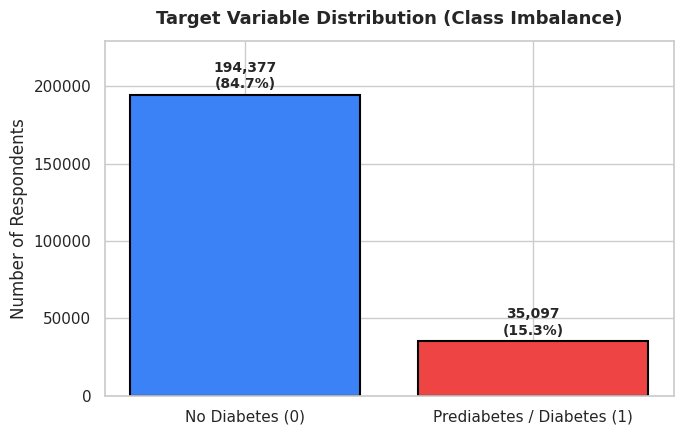

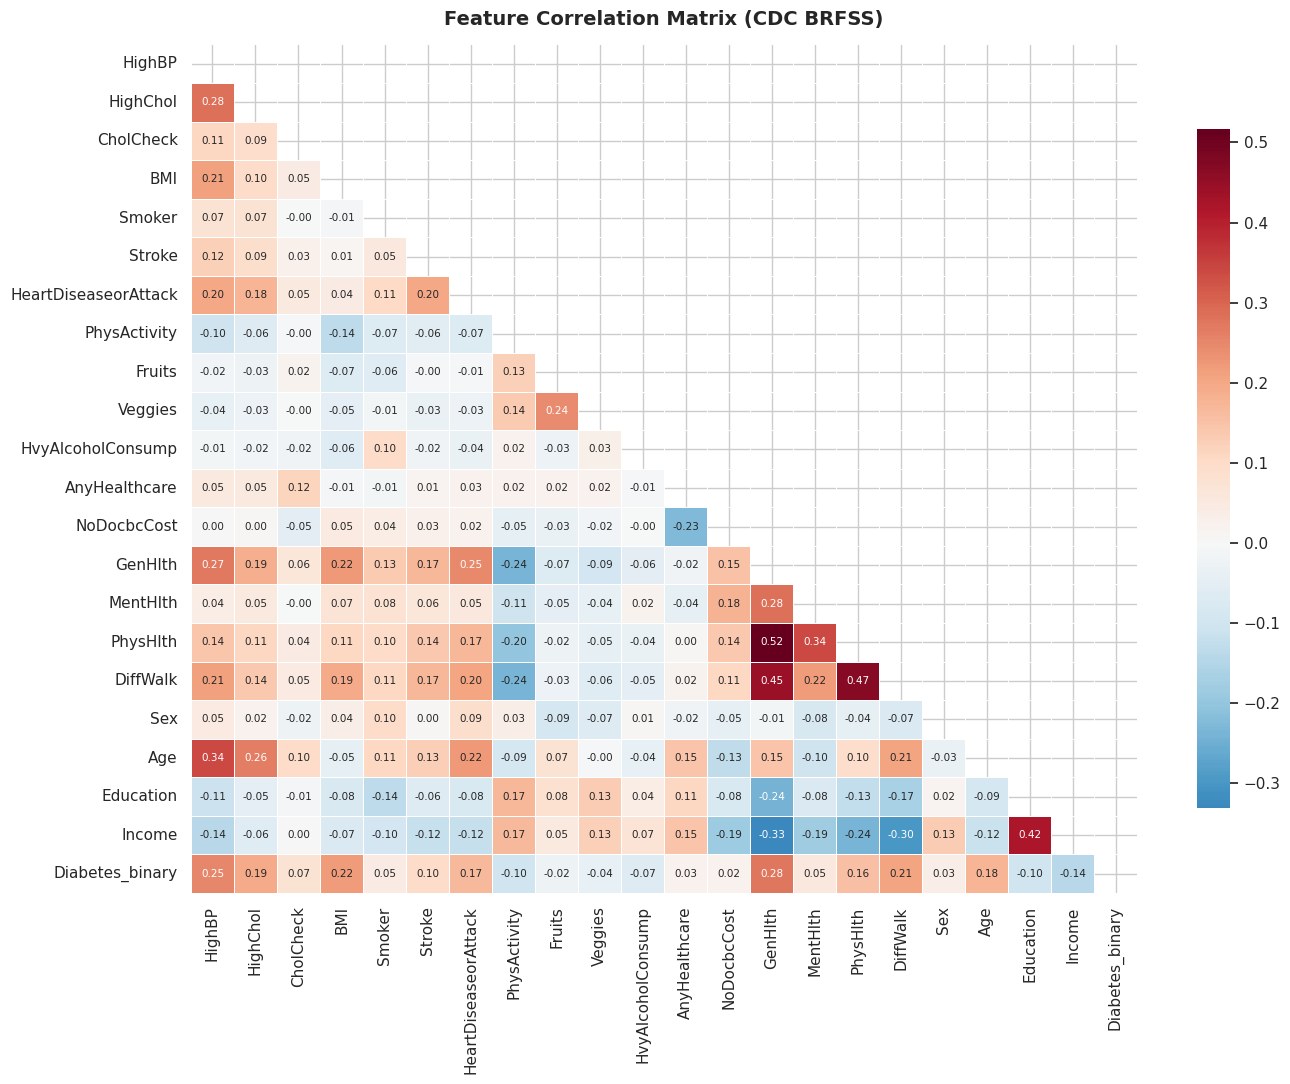

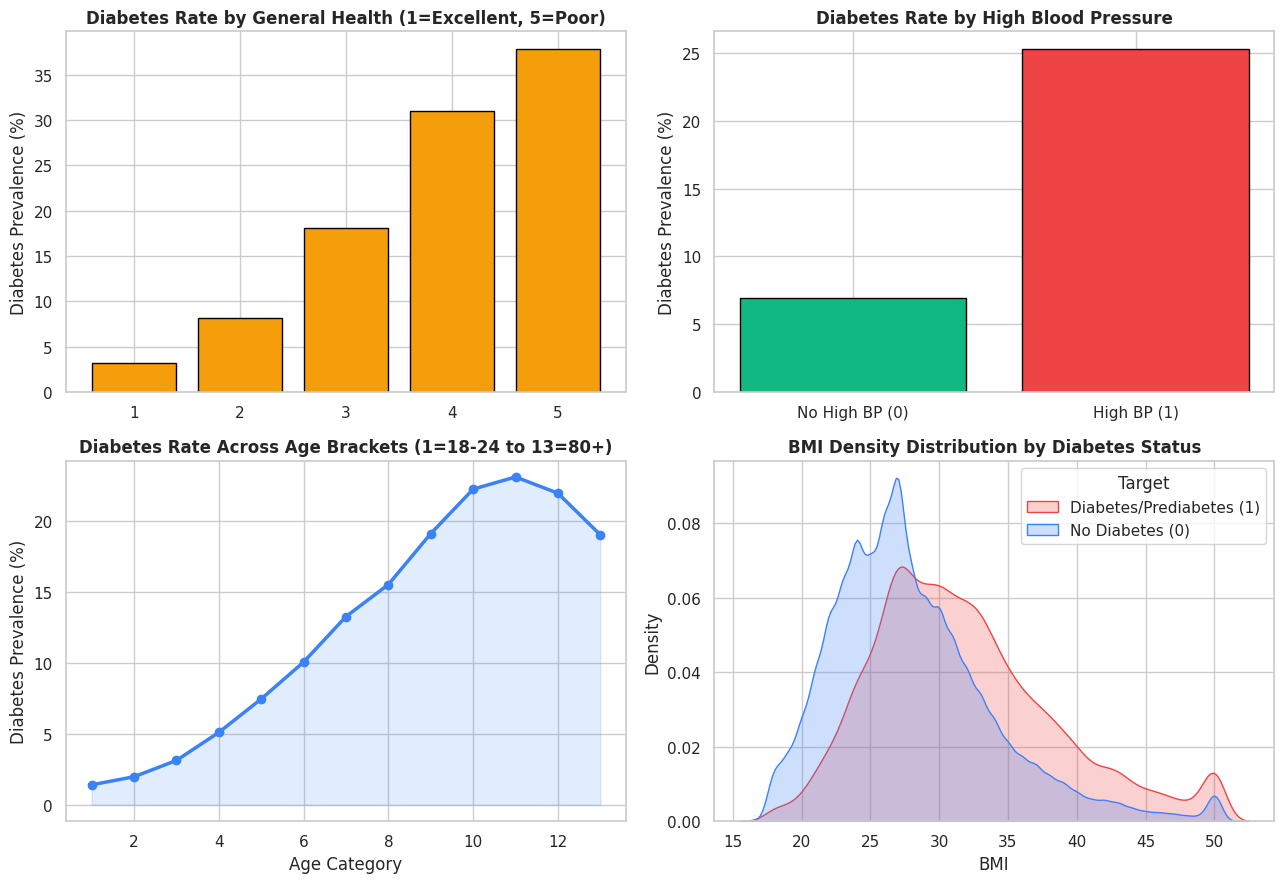

In [4]:
# Plot 1: Target Class Distribution
fig, ax = plt.subplots(figsize=(7, 4.5))
counts = df_clean[target_col].value_counts().sort_index()
labels = ["No Diabetes (0)", "Prediabetes / Diabetes (1)"]
bars = ax.bar(labels, counts.values, color=["#3B82F6", "#EF4444"], edgecolor="black", linewidth=1.5)
for bar, val in zip(bars, counts.values):
    pct = val / len(df_clean) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, val + 2500, f"{val:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontweight="bold", fontsize=10)
ax.set_title("Target Variable Distribution (Class Imbalance)", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Number of Respondents")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig("plots/01_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Feature Correlation Heatmap
fig, ax = plt.subplots(figsize=(14, 11))
corr = df_clean.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, linewidths=0.4, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Feature Correlation Matrix (CDC BRFSS)", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig("plots/02_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: Key Risk Factors vs. Diabetes Prevalence
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 3a: General Health (1=Excellent ... 5=Poor)
gen_rate = df_clean.groupby("GenHlth")[target_col].mean() * 100
axes[0, 0].bar(gen_rate.index, gen_rate.values, color="#F59E0B", edgecolor="black")
axes[0, 0].set_title("Diabetes Rate by General Health (1=Excellent, 5=Poor)", fontweight="bold")
axes[0, 0].set_ylabel("Diabetes Prevalence (%)")
axes[0, 0].set_xticks([1, 2, 3, 4, 5])

# 3b: High Blood Pressure
bp_rate = df_clean.groupby("HighBP")[target_col].mean() * 100
axes[0, 1].bar(["No High BP (0)", "High BP (1)"], bp_rate.values, color=["#10B981", "#EF4444"], edgecolor="black")
axes[0, 1].set_title("Diabetes Rate by High Blood Pressure", fontweight="bold")
axes[0, 1].set_ylabel("Diabetes Prevalence (%)")

# 3c: Age Group (1=18-24 ... 13=80+)
age_rate = df_clean.groupby("Age")[target_col].mean() * 100
axes[1, 0].plot(age_rate.index, age_rate.values, marker="o", linewidth=2.5, color="#3B82F6")
axes[1, 0].fill_between(age_rate.index, age_rate.values, alpha=0.15, color="#3B82F6")
axes[1, 0].set_title("Diabetes Rate Across Age Brackets (1=18-24 to 13=80+)", fontweight="bold")
axes[1, 0].set_xlabel("Age Category")
axes[1, 0].set_ylabel("Diabetes Prevalence (%)")

# 3d: BMI Distribution by Target
sns.kdeplot(data=df_clean, x="BMI", hue=target_col, fill=True, common_norm=False,
            palette={0: "#3B82F6", 1: "#EF4444"}, ax=axes[1, 1])
axes[1, 1].set_title("BMI Density Distribution by Diabetes Status", fontweight="bold")
axes[1, 1].legend(title="Target", labels=["Diabetes/Prediabetes (1)", "No Diabetes (0)"])

plt.tight_layout()
plt.savefig("plots/03_top_features_eda.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Train size: {len(X_train):,} | Test size: {len(X_test):,} | scale_pos_weight: {scale_pos_weight:.2f}")

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=14, min_samples_leaf=20,
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.08,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE
    )
}

results = []
roc_store = {}
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        "model": name,
        "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_test, y_pred)), 4),
        "precision": round(float(precision_score(y_test, y_pred)), 4),
        "recall": round(float(recall_score(y_test, y_pred)), 4),
        "f1": round(float(f1_score(y_test, y_pred)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, y_prob)), 4),
        "pr_auc": round(float(average_precision_score(y_test, y_prob)), 4)
    }
    results.append(metrics)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_store[name] = (fpr, tpr, metrics["roc_auc"])
    trained_models[name] = (model, y_pred, y_prob)

results_df = pd.DataFrame(results).sort_values(by="roc_auc", ascending=False).reset_index(drop=True)
display(results_df)

best_model_name = results_df.loc[0, "model"]
best_model, best_pred, best_prob = trained_models[best_model_name]
print(f"\nBest Model (by ROC-AUC): {best_model_name}")
print("\nClassification Report (Best Model):")
print(classification_report(y_test, best_pred, target_names=["No Diabetes", "Diabetes/Prediabetes"]))

Train size: 183,579 | Test size: 45,895 | scale_pos_weight: 5.54
Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.7281,0.7399,0.3303,0.7569,0.4599,0.8176,0.4431
1,XGBoost,0.7132,0.7400,0.3201,0.7786,0.4537,0.8170,0.4437
2,Logistic Regression,0.7149,0.7342,0.3191,0.7619,0.4498,0.8120,0.4268
3,Decision Tree,0.7005,0.7278,0.3078,0.7671,0.4393,0.8046,0.4210



Best Model (by ROC-AUC): Random Forest

Classification Report (Best Model):
                      precision    recall  f1-score   support

         No Diabetes       0.94      0.72      0.82     38876
Diabetes/Prediabetes       0.33      0.76      0.46      7019

            accuracy                           0.73     45895
           macro avg       0.64      0.74      0.64     45895
        weighted avg       0.85      0.73      0.76     45895



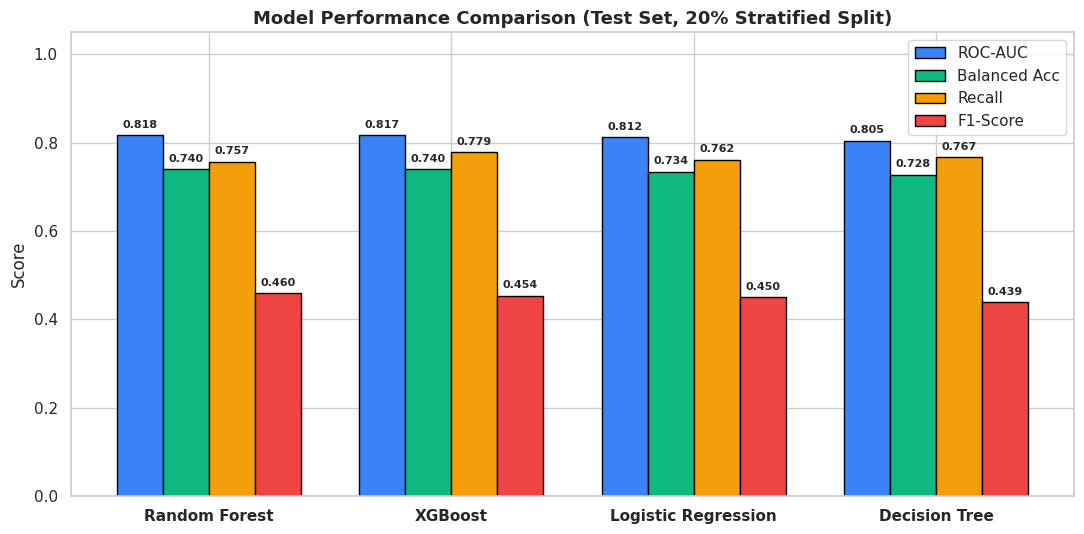

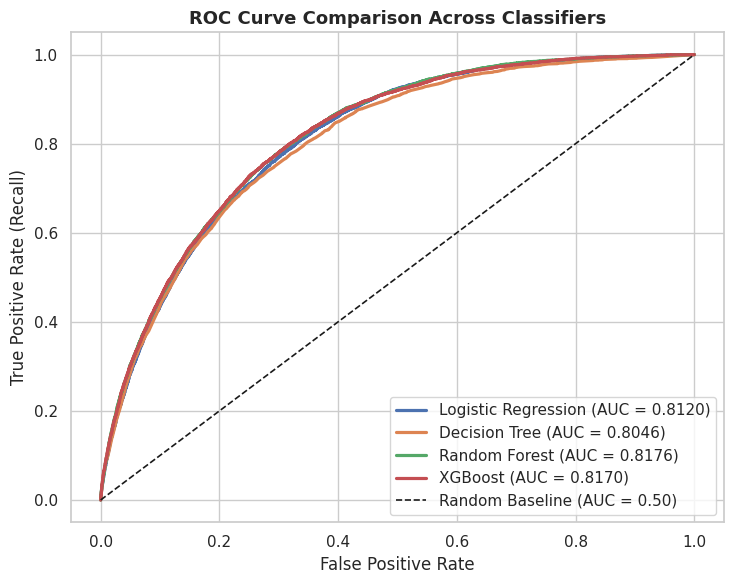

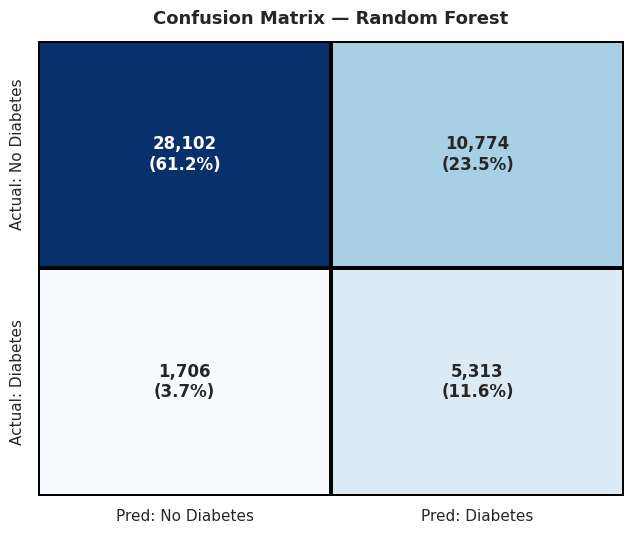

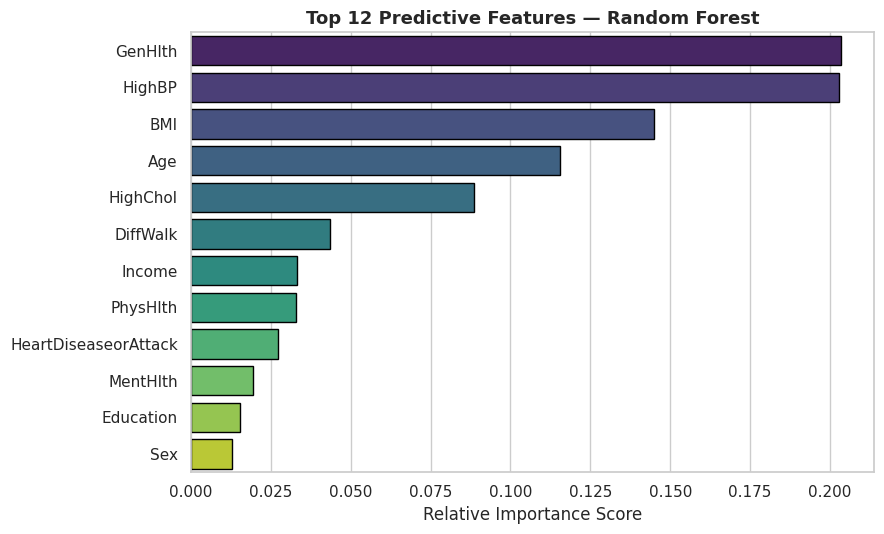

In [6]:
# Plot 4: Multi-Model Performance Comparison
plot_metrics = ["roc_auc", "balanced_accuracy", "recall", "f1"]
plot_labels = ["ROC-AUC", "Balanced Acc", "Recall", "F1-Score"]
x = np.arange(len(results_df))
width = 0.19
colors = ["#3B82F6", "#10B981", "#F59E0B", "#EF4444"]

fig, ax = plt.subplots(figsize=(11, 5.5))
for idx, (m, lbl, col) in enumerate(zip(plot_metrics, plot_labels, colors)):
    vals = results_df[m].values
    bars = ax.bar(x + (idx - 1.5) * width, vals, width, label=lbl, color=col, edgecolor="black")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f"{b.get_height():.3f}",
                ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(results_df["model"], fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison (Test Set, 20% Stratified Split)", fontsize=13, fontweight="bold")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("plots/04_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 5: Multi-Model ROC Curves
fig, ax = plt.subplots(figsize=(7.5, 6))
for name, (fpr, tpr, auc_val) in roc_store.items():
    ax.plot(fpr, tpr, linewidth=2.3, label=f"{name} (AUC = {auc_val:.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Random Baseline (AUC = 0.50)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curve Comparison Across Classifiers", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("plots/05_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 6: Confusion Matrix (Best Model)
cm = confusion_matrix(y_test, best_pred)
cm_pct = cm / cm.sum() * 100
annot = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, linewidths=1.5, linecolor="black",
            xticklabels=["Pred: No Diabetes", "Pred: Diabetes"],
            yticklabels=["Actual: No Diabetes", "Actual: Diabetes"], ax=ax, annot_kws={"size": 12, "weight": "bold"})
ax.set_title(f"Confusion Matrix — {best_model_name}", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("plots/06_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 7: Top 12 Feature Importances
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
else:
    importances = np.abs(best_model.named_steps["clf"].coef_[0])

fi_df = pd.DataFrame({"feature": X.columns, "importance": importances}).sort_values("importance", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis", edgecolor="black", ax=ax)
ax.set_title(f"Top 12 Predictive Features — {best_model_name}", fontsize=13, fontweight="bold")
ax.set_xlabel("Relative Importance Score")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("plots/07_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()